# 07 · Interpretation of the global model with Shapley values

Supports **Section 7.8** of the thesis. The Shapley values are computed by `python src/interpretation.py`
(XGBoost's exact TreeSHAP); this notebook only reads them.

**What is explained.** The forecasts of the test window (4 weekly origins × 7 horizons) of a random sample
of 4,000 series, 112,000 forecasts in all, for the main model (L+E+S+ID, Tweedie), for the same model
without the identifiers (L+E+S) and for the model with the sales of the higher levels of the hierarchy
(L+E+S+ID+H), which was added after the test window had been opened and is read in Section 5 only.

**How to read the values.** The model has a log link, so the contributions are on the log scale: the base
value plus the contributions of a forecast add up to the logarithm of the forecast. A contribution of +0.10
multiplies the forecast by e^0.10 ≈ 1.11, one of −0.10 by 0.90. The importance of an input is the mean of
the absolute value of its contribution over the forecasts; the importance of a group of inputs is the mean
absolute value of the sum of the contributions of its inputs.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import features as F
import m5_data as m5
from plot_style import BLUE_RAMP, SERIES, apply_style, savefig

apply_style()
pd.set_option("display.float_format", "{:,.3f}".format)
SHAP = m5.PROCESSED_DIR / "shap"
RESULTS = ROOT / "results" / "interpretation"
RESULTS.mkdir(parents=True, exist_ok=True)
NAMES = {"LES_tweedie": "L+E+S · Tweedie", "LESID_tweedie": "L+E+S+ID · Tweedie", "LESIDH_tweedie": "L+E+S+ID+H · Tweedie"}
GROUP_NAMES = {"h": "horizon", "L": "L: lags of sales", "E": "E: known in advance", "S": "S: statistics of sales",
               "ID": "ID: identifiers", "H": "H: sales of higher levels"}
CLASSES = ["smooth", "erratic", "intermittent", "lumpy"]

X = pd.read_parquet(SHAP / "inputs.parquet")
series = np.load(SHAP / "series.npy")
stats = pd.read_parquet(m5.PROCESSED_DIR / "series_stats_train.parquet")
cls = stats["sbc_class"].astype(str).to_numpy()[series]
group_of = {F.H_COL: "h"} | {c: g for g, cols in F.GROUPS.items() for c in cols}
shap, base = {}, {}
for key, name in NAMES.items():
    z = np.load(SHAP / f"{key}.npz")
    shap[name] = pd.DataFrame(z["contrib"], columns=z["columns"])
    base[name] = float(z["base"][0])
TOP = NAMES["LESID_tweedie"]  # the main model
HTOP = NAMES["LESIDH_tweedie"]  # the model with the sales of the higher levels, Section 5
print(f"{len(X):,} forecasts of {len(np.unique(series)):,} series; base value of {TOP}: {base[TOP]:.3f} (forecast {np.exp(base[TOP]):.3f} units)")
pd.Series(cls).value_counts().div(28).loc[CLASSES].rename("series in the sample").to_frame().T

112,000 forecasts of 4,000 series; base value of L+E+S+ID · Tweedie: 0.324 (forecast 1.382 units)


,smooth,erratic,intermittent,lumpy
series in the sample,252.000,113.000,"2,927.000",708.000


## 1. Importance of the groups of inputs

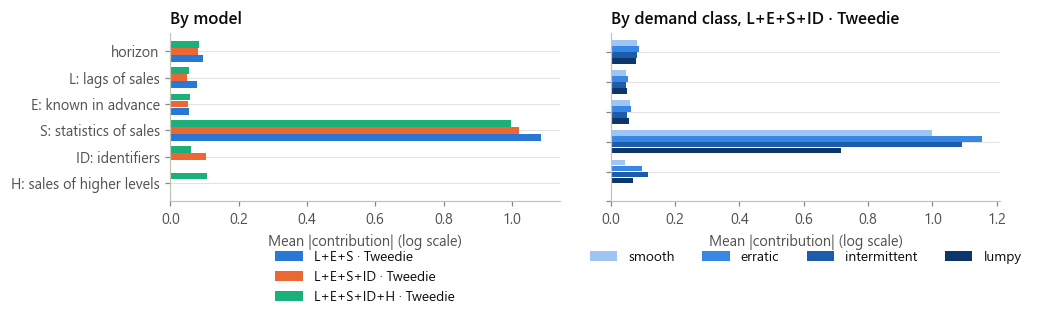

,L+E+S · Tweedie,L+E+S+ID · Tweedie,L+E+S+ID+H · Tweedie,L+E+S+ID · Tweedie · smooth,L+E+S+ID · Tweedie · erratic,L+E+S+ID · Tweedie · intermittent,L+E+S+ID · Tweedie · lumpy
horizon,0.096,0.080,0.085,0.080,0.088,0.081,0.078
L: lags of sales,0.076,0.048,0.055,0.046,0.053,0.047,0.051
E: known in advance,0.055,0.051,0.057,0.058,0.063,0.050,0.055
S: statistics of sales,1.086,1.021,0.999,1.000,1.153,1.091,0.716
ID: identifiers,NaN,0.103,0.060,0.043,0.096,0.117,0.070
H: sales of higher levels,NaN,NaN,0.108,NaN,NaN,NaN,NaN


In [2]:
def group_importance(s, mask=None):
    s = s if mask is None else s[mask]
    g = s.T.groupby([group_of[c] for c in s.columns]).sum().T
    return g.abs().mean().reindex(list(GROUP_NAMES)).rename(GROUP_NAMES)


groups = pd.DataFrame({name: group_importance(s) for name, s in shap.items()})
by_class = pd.DataFrame({c: group_importance(shap[TOP], cls == c) for c in CLASSES})
groups.to_csv(RESULTS / "group_importance.csv")
by_class.to_csv(RESULTS / "group_importance_by_class.csv")
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.2))
y = np.arange(len(groups))[::-1]
for k, (name, color) in enumerate(zip(groups.columns, SERIES)):
    axes[0].barh(y + (0.27 * k - 0.27), groups[name].fillna(0), 0.26, color=color, label=name)
axes[0].set_yticks(y, groups.index)
axes[0].set_xlabel("Mean |contribution| (log scale)")
axes[0].set_title("By model")
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncols=1)
for k, (c, color) in enumerate(zip(CLASSES, BLUE_RAMP[1::2])):
    axes[1].barh(y + (0.3 - 0.2 * k), by_class[c], 0.19, color=color, label=c)
axes[1].set_yticks(y, [])
axes[1].set_xlabel("Mean |contribution| (log scale)")
axes[1].set_title(f"By demand class, {TOP}")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncols=4)
fig.tight_layout()
savefig(fig, "group_importance", subdir="interpretation")
plt.show()
pd.concat([groups, by_class.add_prefix(f"{TOP} · ")], axis=1)

## 2. Single inputs

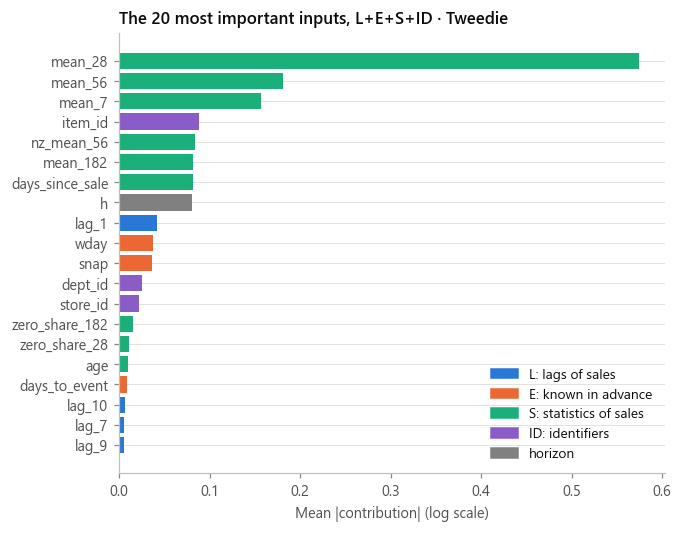

the 10 most important inputs carry 86% of the total importance, the 20 most important 95%


,group,L+E+S · Tweedie,L+E+S+ID · Tweedie,L+E+S+ID+H · Tweedie
mean_28,S,0.694,0.574,0.594
mean_56,S,0.122,0.181,0.179
mean_7,S,0.146,0.157,0.125
item_id,ID,NaN,0.088,0.050
nz_mean_56,S,0.054,0.084,0.074
mean_182,S,0.180,0.082,0.075
days_since_sale,S,0.106,0.081,0.079
h,h,0.096,0.080,0.085
lag_1,L,0.047,0.042,0.042
wday,E,0.036,0.038,0.042


In [3]:
imp = pd.DataFrame({name: s.abs().mean() for name, s in shap.items()})
imp.insert(0, "group", [group_of[c] for c in imp.index])
imp = imp.sort_values(TOP, ascending=False)
imp.to_csv(RESULTS / "feature_importance.csv")
top = imp.head(20)[::-1]
palette = dict(zip(["h", "L", "E", "S", "ID", "H"], ["0.5", SERIES[0], SERIES[1], SERIES[2], "#8a5cc7", "#c2410c"]))
fig, ax = plt.subplots(figsize=(6.4, 5.2))
ax.barh(range(len(top)), top[TOP], color=[palette[g] for g in top["group"]])
ax.set_yticks(range(len(top)), top.index)
ax.set_xlabel("Mean |contribution| (log scale)")
ax.set_title(f"The 20 most important inputs, {TOP}")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=palette[g]) for g in ["L", "E", "S", "ID", "h"]],
          labels=[GROUP_NAMES[g] for g in ["L", "E", "S", "ID", "h"]], loc="lower right")
savefig(fig, "feature_importance", subdir="interpretation")
plt.show()
share = imp[TOP].cumsum() / imp[TOP].sum()
print(f"the 10 most important inputs carry {share.iloc[9]:.0%} of the total importance, the 20 most important {share.iloc[19]:.0%}")
imp.head(20)

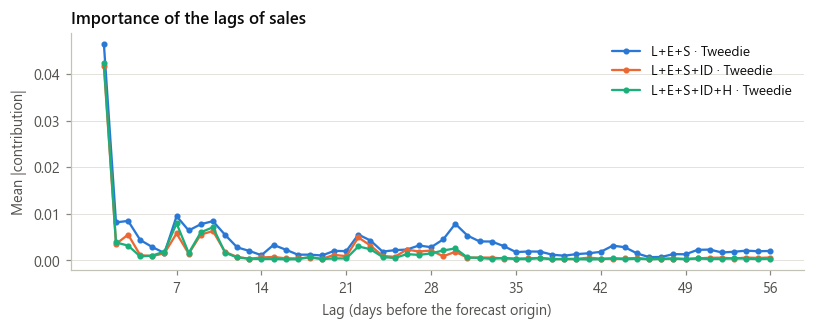

lags 1-7 carry 54% of the importance of the 56 lags


In [4]:
lags = imp.loc[F.LAG_COLS]
fig, ax = plt.subplots(figsize=(8.6, 2.8))
for name, color in zip(shap, SERIES):
    ax.plot(range(1, F.N_LAGS + 1), lags[name], color=color, marker="o", ms=3, label=name)
ax.set_xticks(range(7, F.N_LAGS + 1, 7))
ax.set_xlabel("Lag (days before the forecast origin)")
ax.set_ylabel("Mean |contribution|")
ax.set_title("Importance of the lags of sales")
ax.legend()
savefig(fig, "lag_importance", subdir="interpretation")
plt.show()
print(f"lags 1-7 carry {lags[TOP].iloc[:7].sum() / lags[TOP].sum():.0%} of the importance of the 56 lags")

## 3. How the main inputs move the forecast

Median contribution (line) and the middle half of the contributions (band) by the value of the input. The
contributions are on the log scale: a contribution of 0.5 multiplies the forecast by 1.65, one of −0.5 by 0.61.

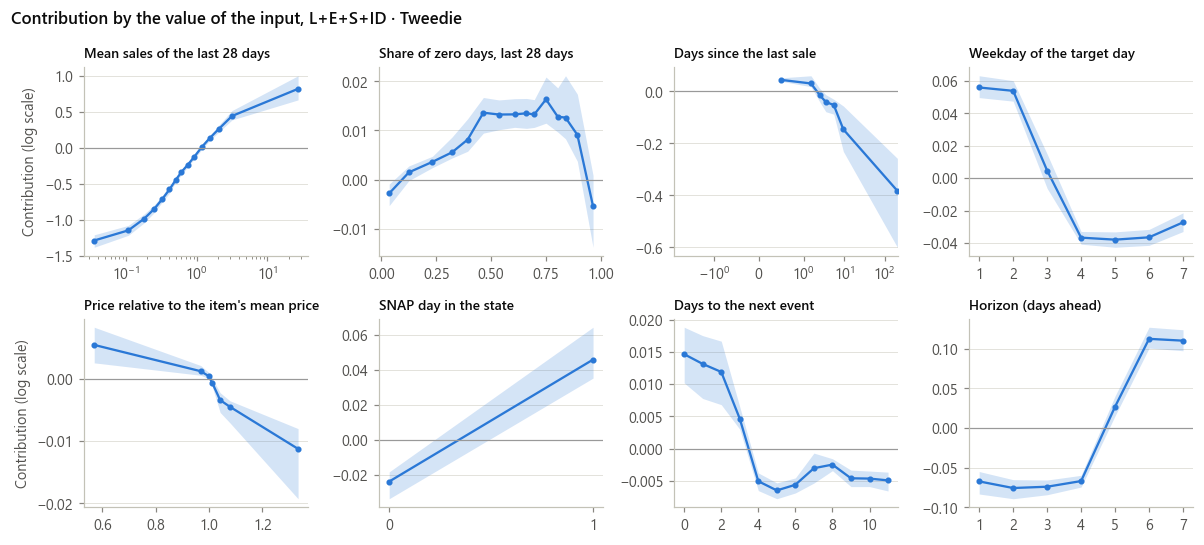

,lowest median contribution,highest median contribution,factor between them
mean_28,-1.290,0.815,8.209
zero_share_28,-0.005,0.016,1.022
days_since_sale,-0.383,0.044,1.533
wday,-0.038,0.056,1.098
rel_price,-0.011,0.005,1.017
snap,-0.024,0.046,1.072
days_to_event,-0.007,0.015,1.021
h,-0.076,0.112,1.207


In [5]:
PANELS = [("mean_28", "Mean sales of the last 28 days"), ("zero_share_28", "Share of zero days, last 28 days"),
          ("days_since_sale", "Days since the last sale"), ("wday", "Weekday of the target day"),
          ("rel_price", "Price relative to the item's mean price"), ("snap", "SNAP day in the state"),
          ("days_to_event", "Days to the next event"), ("h", "Horizon (days ahead)")]
s = shap[TOP]
fig, axes = plt.subplots(2, 4, figsize=(11, 5))
dep = {}
for ax, (col, title) in zip(axes.ravel(), PANELS):
    x = X[col].astype(float)
    if x.nunique() <= 12:
        key = x
    else:
        edges = np.unique(np.nanquantile(x, np.linspace(0, 1, 16)))
        key = pd.cut(x, edges, include_lowest=True, duplicates="drop").map(lambda b: b.mid).astype(float)
    q = s[col].groupby(key.to_numpy()).quantile([0.25, 0.5, 0.75]).unstack()
    dep[col] = q
    ax.fill_between(q.index, q[0.25], q[0.75], color=SERIES[0], alpha=0.2, lw=0)
    ax.plot(q.index, q[0.5], color=SERIES[0], marker="o", ms=3)
    ax.axhline(0, color="0.6", lw=0.8)
    if col == "mean_28":
        ax.set_xscale("log")
    if col == "days_since_sale":
        ax.set_xscale("symlog", linthresh=1)
    if x.nunique() <= 12:
        ax.set_xticks(sorted(x.unique()) if x.nunique() <= 7 else range(0, 12, 2))
    ax.set_title(title, fontsize=9)
axes[0, 0].set_ylabel("Contribution (log scale)")
axes[1, 0].set_ylabel("Contribution (log scale)")
fig.suptitle(f"Contribution by the value of the input, {TOP}", x=0.01, ha="left", fontsize=11, fontweight="semibold")
fig.tight_layout()
savefig(fig, "dependence", subdir="interpretation")
plt.show()
pd.concat(dep).rename_axis(["input", "value"]).to_csv(RESULTS / "dependence.csv")
pd.DataFrame({col: {"lowest median contribution": q[0.5].min(), "highest median contribution": q[0.5].max(),
                    "factor between them": np.exp(q[0.5].max() - q[0.5].min())} for col, q in dep.items()}).T

## 4. What the identifiers replace

The identifiers are the only difference between the models L+E+S and L+E+S+ID. The table compares the
importance of each group, and of the identifiers one by one, to show which inputs lose importance when the
model knows which series a row belongs to.

In [6]:
MID = NAMES["LESID_tweedie"]
ids = imp.loc[F.ID_COLS, [MID]].rename(columns={MID: "mean |contribution|"})
ids["share of the ID group"] = ids["mean |contribution|"] / ids["mean |contribution|"].sum()
change = groups[[NAMES["LES_tweedie"], MID]].assign(change=groups[MID] - groups[NAMES["LES_tweedie"]])
item = shap[MID]["item_id"]
per_series = item.groupby(series).mean()
print(f"item_id: contribution of a series (mean over its forecasts) between {per_series.quantile(0.05):+.2f} and "
      f"{per_series.quantile(0.95):+.2f} for 90% of the series, i.e. a factor of {np.exp(per_series.quantile(0.05)):.2f} to "
      f"{np.exp(per_series.quantile(0.95)):.2f}")
display(change)
ids

item_id: contribution of a series (mean over its forecasts) between -0.27 and +0.05 for 90% of the series, i.e. a factor of 0.77 to 1.06


,L+E+S · Tweedie,L+E+S+ID · Tweedie,change
horizon,0.096,0.080,-0.016
L: lags of sales,0.076,0.048,-0.028
E: known in advance,0.055,0.051,-0.004
S: statistics of sales,1.086,1.021,-0.065
ID: identifiers,NaN,0.103,NaN
H: sales of higher levels,NaN,NaN,NaN


,mean |contribution|,share of the ID group
item_id,0.088,0.631
dept_id,0.025,0.180
cat_id,0.003,0.021
store_id,0.022,0.158
state_id,0.002,0.011


## 5. What the sales of the higher levels add

Group H gives the model the recent sales of the item in all stores, of the department in the store and of
the whole store. This section reads the model L+E+S+ID+H: the importance of its nine new inputs, their
importance by demand class, and the change of the importance of the other groups against the main model.

inputs that lose the most importance with group H: item_id (-0.038), mean_7 (-0.032), dept_id (-0.015), nz_mean_56 (-0.010), mean_182 (-0.007)


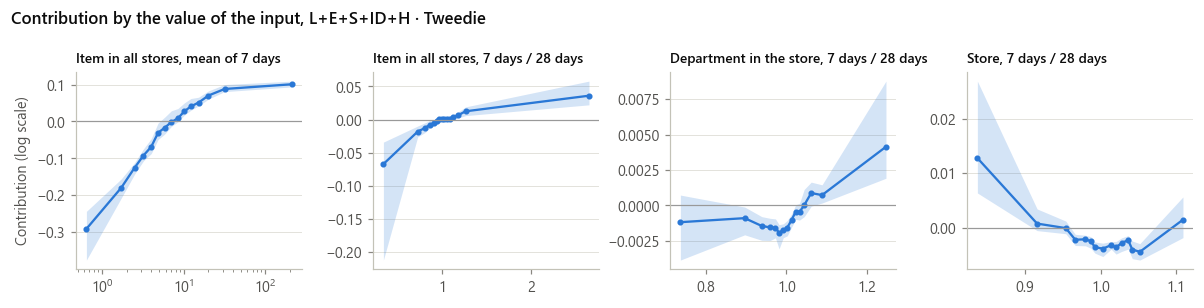

,L+E+S+ID · Tweedie,L+E+S+ID+H · Tweedie,change
horizon,0.080,0.085,0.004
L: lags of sales,0.048,0.055,0.007
E: known in advance,0.051,0.057,0.006
S: statistics of sales,1.021,0.999,-0.022
ID: identifiers,0.103,0.060,-0.043
H: sales of higher levels,NaN,0.108,0.108


,smooth,erratic,intermittent,lumpy
horizon,0.084,0.092,0.085,0.082
L: lags of sales,0.051,0.057,0.056,0.055
E: known in advance,0.065,0.068,0.055,0.060
S: statistics of sales,0.926,1.077,1.075,0.699
ID: identifiers,0.032,0.050,0.066,0.046
H: sales of higher levels,0.111,0.147,0.109,0.099


,lowest median contribution,highest median contribution,factor between them
item_all_mean_7,-0.291,0.101,1.479
item_all_trend,-0.067,0.036,1.109
dept_store_trend,-0.002,0.004,1.006
store_trend,-0.004,0.013,1.017


,mean |contribution|,share of the H group,rank among all inputs
item_all_mean_7,0.091,0.615,4
item_all_mean_28,0.006,0.040,24
item_all_trend,0.023,0.155,14
dept_store_mean_7,0.007,0.047,22
dept_store_mean_28,0.004,0.028,29
dept_store_trend,0.002,0.015,38
store_mean_7,0.002,0.015,39
store_mean_28,0.008,0.053,19
store_trend,0.005,0.031,26


In [7]:
hier = imp.loc[F.HIER_COLS, [HTOP]].rename(columns={HTOP: "mean |contribution|"})
hier["share of the H group"] = hier["mean |contribution|"] / hier["mean |contribution|"].sum()
hier["rank among all inputs"] = imp[HTOP].rank(ascending=False).loc[F.HIER_COLS].astype(int)
change_h = groups[[MID, HTOP]].assign(change=groups[HTOP].fillna(0) - groups[MID].fillna(0))
by_class_h = pd.DataFrame({c: group_importance(shap[HTOP], cls == c) for c in CLASSES})
by_class_h.to_csv(RESULTS / "group_importance_by_class_hierarchy.csv")
moved = (imp[HTOP] - imp[MID]).drop(F.HIER_COLS).sort_values()
print("inputs that lose the most importance with group H:", ", ".join(f"{c} ({v:+.3f})" for c, v in moved.head(5).items()))
HP = [("item_all_mean_7", "Item in all stores, mean of 7 days"), ("item_all_trend", "Item in all stores, 7 days / 28 days"),
      ("dept_store_trend", "Department in the store, 7 days / 28 days"), ("store_trend", "Store, 7 days / 28 days")]
fig, axes = plt.subplots(1, 4, figsize=(11, 2.8))
dep_h = {}
for ax, (col, title) in zip(axes, HP):
    x = X[col].astype(float)
    edges = np.unique(np.nanquantile(x, np.linspace(0, 1, 16)))
    cut = pd.cut(x, edges, include_lowest=True, duplicates="drop")
    key = cut.cat.rename_categories([b.mid for b in cut.cat.categories]).astype(float)
    q = shap[HTOP][col].groupby(key.to_numpy()).quantile([0.25, 0.5, 0.75]).unstack()
    dep_h[col] = q
    ax.fill_between(q.index, q[0.25], q[0.75], color=SERIES[0], alpha=0.2, lw=0)
    ax.plot(q.index, q[0.5], color=SERIES[0], marker="o", ms=3)
    ax.axhline(0, color="0.6", lw=0.8)
    if col == "item_all_mean_7":
        ax.set_xscale("log")
    ax.set_title(title, fontsize=9)
axes[0].set_ylabel("Contribution (log scale)")
fig.suptitle(f"Contribution by the value of the input, {HTOP}", x=0.01, ha="left", fontsize=11, fontweight="semibold")
fig.tight_layout()
savefig(fig, "dependence_hierarchy", subdir="interpretation")
plt.show()
pd.concat(dep_h).rename_axis(["input", "value"]).to_csv(RESULTS / "dependence_hierarchy.csv")
display(change_h)
display(by_class_h)
display(pd.DataFrame({col: {"lowest median contribution": q[0.5].min(), "highest median contribution": q[0.5].max(),
                            "factor between them": np.exp(q[0.5].max() - q[0.5].min())} for col, q in dep_h.items()}).T)
hier

## Key findings

Points 1–6 are about the main model (L+E+S+ID, Tweedie), point 7 about the model with the sales of the
higher levels (L+E+S+ID+H), which was added after the test window had been opened.

1. **The model is first of all a smoothed level of recent sales.** The statistics of sales carry about ten
   times more importance than any other group (1.02 against 0.05–0.10), and the mean of the last 28 days
   alone more than half of the total. This is the information the intermittent-demand methods use (ADIDA and
   TSB are smoothed levels), which is consistent with the small gain over them on single series (Section
   7.5).
2. **Single lags matter little once the statistics are present.** The 56 lags together have an importance of
   0.05; the last seven days carry 54% of it, and yesterday's sales the most.
3. **The inputs known in advance have small but systematic effects.** A SNAP day raises the forecast by about
   7%, a weekend day by about 10% against a mid-week day, the days just before an event by 1–2%; the relative
   price changes it by about 1–2% over its whole range. These effects are the same for many series at once,
   which is why they improve the aggregated levels much more than single series (Sections 7.4, 7.6).
4. **The horizon carries part of the weekly pattern.** Every origin is a Sunday, so horizons 6 and 7 are
   always a Saturday and a Sunday. The contribution of the horizon (−0.07 for days 1–4, +0.11 for days 6–7)
   is therefore mostly a weekday effect and cannot be read as a loss of accuracy with the horizon.
5. **The identifiers replace the long-run statistics.** `item_id` is the fourth most important input. With the
   identifiers the mean of the last 182 days, the share of zero days of the last 182 days and the age of the
   series lose more than half of their importance: the model reads the long-run level of a series from its
   identity instead. The identifiers matter most for intermittent series (0.12) and least for smooth ones
   (0.04).
6. **Long gaps lower the forecast.** More than a week without a sale lowers the forecast by about 14%, a very
   long gap by about 30%, beyond what the recent mean already says: the model has learned the obsolescence
   that TSB models directly.
7. **The sales of the higher levels are mostly one input, and they replace part of the identifiers.** In the
   model L+E+S+ID+H, group H has an importance of 0.11, the second largest after the statistics, and 62% of
   it is the mean sales of the item in all stores over the last 7 days (the fourth most important input);
   its trend (7 days against 28 days) carries another 16%. The sales of the department and of the whole store
   matter little (under 0.01 each). With group H the importance of the identifiers falls from 0.10 to 0.06
   (`item_id` from 0.088 to 0.050) and that of the series' own 7-day mean from 0.16 to 0.13: what the model
   needed from the identity of the item is partly how the item sells elsewhere right now. An item that sells
   well in all stores raises the forecast by up to 10%, one that hardly sells anywhere lowers it by up to
   25%. Group H is most important for erratic series (0.15) and least for lumpy ones (0.10).
8. **Limits.** Shapley values describe what the model uses, not what causes sales. The means over 7, 28, 56
   and 182 days are strongly correlated, and so are the series' own means and the means of the item in all
   stores, so their importance is shared among them and only their sum is reliable. The values are on the
   log scale and come from one model (seed 0) and one window.